<p style="background-color: #4CAF50; font-size: 48px; font-weight: bold; color: white; padding: 20px; text-align: center;">
🧹 Data Preparation 
</p>


In [1]:
#Import librairies
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math 
from scipy.stats import pearsonr
import scipy.stats as stats
from plotly.subplots import make_subplots
from scipy.stats import shapiro
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
from sklearn.feature_selection import RFE
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings("ignore") 
from sklearn.preprocessing import LabelEncoder,OneHotEncoder
from sklearn import preprocessing
import plotly.graph_objects as go
import plotly.express as px
import missingno as msno
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy.stats import skew, shapiro
from scipy.stats import boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.preprocessing import StandardScaler
import itertools
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import RandomForestRegressor
import shap
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import MinMaxScaler
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import EditedNearestNeighbours
from collections import Counter
from sklearn.feature_selection import SelectKBest
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from prettytable import PrettyTable
import featuretools as ft

In [2]:
#import data
data = pd.read_csv(
    'C:/Users/Mega-Pc/Freelance/data/ecommerce/data.csv',encoding='ISO-8859-1')

## 🔄 Check for duplicates

In [3]:
duplicate_count = data.duplicated().sum()
print(f'Number of duplicate records: {duplicate_count}')


Number of duplicate records: 5268


In [4]:
# drop duplicates
data = data.drop_duplicates()

# Verify removal
duplicate_count_after = data.duplicated().sum()
print(f'Number of duplicate records after dropping: {duplicate_count_after}')

Number of duplicate records after dropping: 0


## Missing columns

In [5]:
missing_counts = data.isnull().sum()
missing_percent = (missing_counts / len(data)) * 100

missing_df = pd.DataFrame({
    'MissingCount': missing_counts,
    'MissingPercent': missing_percent
})

print(missing_df)


             MissingCount  MissingPercent
InvoiceNo               0        0.000000
StockCode               0        0.000000
Description          1454        0.270945
Quantity                0        0.000000
InvoiceDate             0        0.000000
UnitPrice               0        0.000000
CustomerID         135037       25.163377
Country                 0        0.000000


In [6]:
# Drop rows with missing CustomerID
data = data.dropna(subset=['CustomerID'])

#Fill Description missing values with unknown 

data['Description'] = data['Description'].fillna('Unknown')



In [7]:
missing_counts = data.isnull().sum()
missing_percent = (missing_counts / len(data)) * 100

missing_df = pd.DataFrame({
    'MissingCount': missing_counts,
    'MissingPercent': missing_percent
})

print(missing_df)


             MissingCount  MissingPercent
InvoiceNo               0             0.0
StockCode               0             0.0
Description             0             0.0
Quantity                0             0.0
InvoiceDate             0             0.0
UnitPrice               0             0.0
CustomerID              0             0.0
Country                 0             0.0


> **Missing Values Handling**
>
> - `Description`: missing values filled with `"Unknown"` (0.27% of rows)
> - `CustomerID`: missing values dropped (25% of rows)


## ✨ Data Transformation

## Handle outliers by capping them 

In [8]:
#data
num_cols = data.select_dtypes(include=['int64', 'float64']).columns
num_cols = [col for col in num_cols if col != 'CustomerID']
outliers_info = []

for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
    
    outliers_info.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers Count': len(outliers),
        'Total Points': len(data)
    })

outliers_df = pd.DataFrame(outliers_info)
print(outliers_df)


     Feature  Lower Bound  Upper Bound  Outliers Count  Total Points
0   Quantity        -13.0         27.0           26646        401604
1  UnitPrice         -2.5          7.5           35802        401604


In [9]:
def handle_outliers(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[column] = np.clip(df[column], lower_bound, upper_bound)
    return df

for col in num_cols:
    data = handle_outliers(data, col)


In [10]:
# results after capping outliers
outliers_info = []

for col in num_cols:
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data[col] < lower_bound) | (data[col] > upper_bound)]
    
    outliers_info.append({
        'Feature': col,
        'Lower Bound': lower_bound,
        'Upper Bound': upper_bound,
        'Outliers Count': len(outliers),
        'Total Points': len(data)
    })

outliers_df = pd.DataFrame(outliers_info)
print(outliers_df)


     Feature  Lower Bound  Upper Bound  Outliers Count  Total Points
0   Quantity        -13.0         27.0               0        401604
1  UnitPrice         -2.5          7.5               0        401604


## Feature Engineering

In [11]:
# convert InvoiceDate to datetime
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'], errors='coerce')

In [12]:
# transaction-level features

# TotalPrice 
data['TotalPrice'] = data['Quantity'] * data['UnitPrice']

# Description text features
data['DescriptionLength'] = data['Description'].apply(len)
data['NumWordsInDescription'] = data['Description'].apply(lambda x: len(x.split()))

# Invoice type flags
data['IsReturn'] = (data['Quantity'] < 0).astype(int)


In [13]:
# Temporal features

data['InvoiceHour'] = data['InvoiceDate'].dt.hour
data['InvoiceDayOfWeek'] = data['InvoiceDate'].dt.dayofweek  # monday=0
data['InvoiceMonth'] = data['InvoiceDate'].dt.month
data['InvoiceQuarter'] = data['InvoiceDate'].dt.quarter
data['IsWeekend'] = data['InvoiceDayOfWeek'].isin([5,6]).astype(int)
# flag for holiday season (Nov-Dec)
data['IsHolidaySeason'] = data['InvoiceMonth'].isin([11,12]).astype(int)

In [14]:
# Aggregate features


# Invoice-level aggregation
invoice_agg = data.groupby('InvoiceNo').agg(
    NumUniqueItems=('StockCode','nunique'),
    TotalQuantity=('Quantity','sum'),
    AvgPricePerItem=('TotalPrice', lambda x: x.sum()/x.count())
).reset_index()

data = data.merge(invoice_agg, on='InvoiceNo', how='left')

# Customer-level aggregation
customer_agg = data.groupby('CustomerID').agg(
    NumTransactions=('InvoiceNo','nunique'),
    TotalSpent=('TotalPrice','sum'),
    AvgTransactionValue=('TotalPrice','mean'),
    MaxTransactionValue=('TotalPrice','max'),
    AvgItemsPerTransaction=('Quantity','mean'),
    ReturnRate=('IsReturn','mean'),
    NumUniqueItemsBought=('StockCode','nunique'),
    FirstPurchase=('InvoiceDate','min'),
    LastPurchase=('InvoiceDate','max')
).reset_index()

# Recency & Tenure
customer_agg['RecencyDays'] = (pd.Timestamp.now() - customer_agg['LastPurchase']).dt.days
customer_agg['TenureDays'] = (customer_agg['LastPurchase'] - customer_agg['FirstPurchase']).dt.days

data = data.merge(customer_agg, on='CustomerID', how='left')

# Product-level aggregation
product_agg = data.groupby('StockCode').agg(
    TotalQuantitySold=('Quantity','sum'),
    TotalRevenueGenerated=('TotalPrice','sum'),
    AvgUnitPriceSold=('UnitPrice','mean'),
    NumUniqueCustomers=('CustomerID','nunique')
).reset_index()

data = data.merge(product_agg, on='StockCode', how='left')

In [15]:
# Interaction features

# price deviation from product average
data['PricePerUnitDeviation'] = data['UnitPrice'] / data['AvgUnitPriceSold']

#fraction of customer's transactions containing this product
cust_prod = data.groupby(['CustomerID','StockCode']).size().reset_index(name='CustProdCount')
data = data.merge(cust_prod, on=['CustomerID','StockCode'], how='left')
data['CustomerProductAffinity'] = data['CustProdCount'] / data['NumTransactions']

# invoice diversity: unique products per invoice / total items in invoice
data['InvoiceDiversity'] = data['NumUniqueItems'] / data['TotalQuantity']

# country-level spending 
country_avg = data.groupby('Country')['TotalPrice'].mean().reset_index(name='CountryAvgSpend')
data = data.merge(country_avg, on='Country', how='left')
data['CountryAvgSpendDeviation'] = data['TotalPrice'] - data['CountryAvgSpend']

data.drop(columns=['CustProdCount'], inplace=True)


## Semantic product clustering

Batches:   0%|          | 0/12551 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



n_clusters=5 -> CH=10717.30, DB=4.34
n_clusters=10 -> CH=8296.89, DB=3.84
n_clusters=15 -> CH=7291.66, DB=3.28
n_clusters=20 -> CH=6291.67, DB=3.39
n_clusters=25 -> CH=5769.61, DB=3.07
n_clusters=30 -> CH=5416.92, DB=3.01


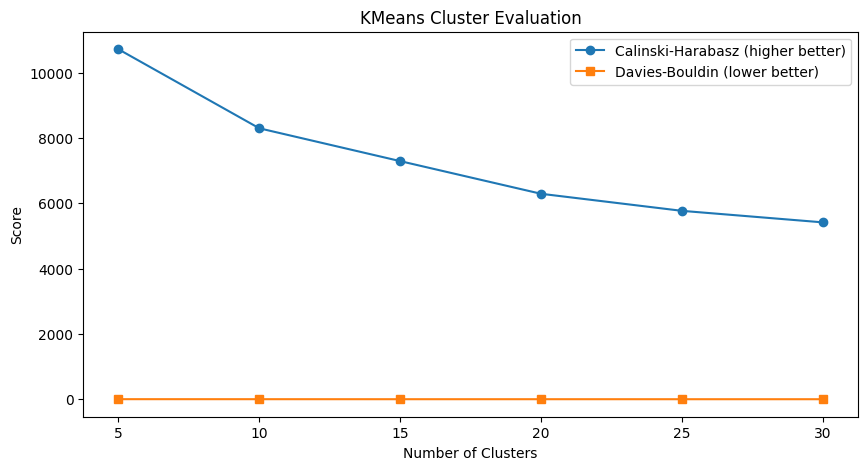


Recommended number of clusters: 5


In [16]:
from sentence_transformers import SentenceTransformer
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, davies_bouldin_score



# generate embeddings

model = SentenceTransformer('all-MiniLM-L12-v2')
descriptions = data['Description'].dropna().tolist()
embeddings = model.encode(descriptions, show_progress_bar=True)
embeddings = np.array(embeddings)


# evaluate multiple cluster numbers

cluster_range = range(5, 31, 5)  # 5, 10, 15, 20, 25, 30 clusters
ch_scores = []
db_scores = []

for n_clusters in cluster_range:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42)
    labels = kmeans.fit_predict(embeddings)
    
    ch = calinski_harabasz_score(embeddings, labels)
    db = davies_bouldin_score(embeddings, labels)
    
    ch_scores.append(ch)
    db_scores.append(db)
    
    print(f"n_clusters={n_clusters} -> CH={ch:.2f}, DB={db:.2f}")


# plot the scores

plt.figure(figsize=(10,5))
plt.plot(cluster_range, ch_scores, marker='o', label='Calinski-Harabasz (higher better)')
plt.plot(cluster_range, db_scores, marker='s', label='Davies-Bouldin (lower better)')
plt.xlabel('Number of Clusters')
plt.ylabel('Score')
plt.title('KMeans Cluster Evaluation')
plt.legend()
plt.show()


#choose the best cluster number

best_index = np.argmax(ch_scores / np.array(db_scores))  
best_n_clusters = cluster_range[best_index]
print(f"\nRecommended number of clusters: {best_n_clusters}")

In [17]:
# KMeans clustering
n_clusters = best_n_clusters
kmeans = KMeans(n_clusters=n_clusters, random_state=42) 
cluster_labels = kmeans.fit_predict(embeddings) 
data.loc[data['Description'].notna(), 'ProductClusterSemantic'] = cluster_labels

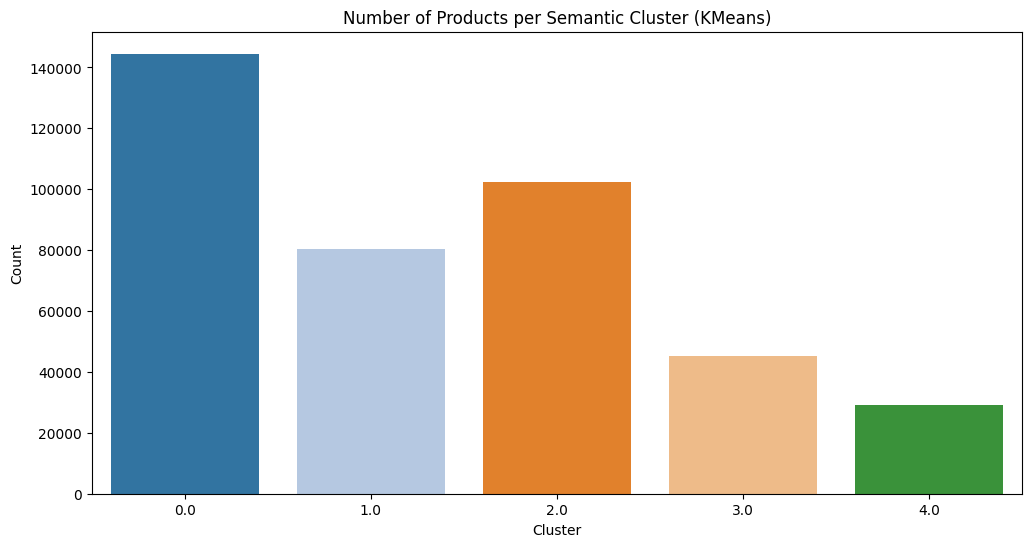


--- Cluster 0 ---
KNITTED UNION FLAG HOT WATER BOTTLE
HAND WARMER UNION JACK
HAND WARMER RED POLKA DOT
POPPY'S PLAYHOUSE BEDROOM 
POPPY'S PLAYHOUSE KITCHEN

--- Cluster 1 ---
SET 7 BABUSHKA NESTING BOXES
BOX OF 6 ASSORTED COLOUR TEASPOONS
BOX OF VINTAGE JIGSAW BLOCKS 
BOX OF VINTAGE ALPHABET BLOCKS
JAM MAKING SET WITH JARS

--- Cluster 2 ---
WHITE HANGING HEART T-LIGHT HOLDER
CREAM CUPID HEARTS COAT HANGER
RED WOOLLY HOTTIE WHITE HEART.
GLASS STAR FROSTED T-LIGHT HOLDER
ASSORTED COLOUR BIRD ORNAMENT

--- Cluster 3 ---
RED COAT RACK PARIS FASHION
BLUE COAT RACK PARIS FASHION
SPACEBOY LUNCH BOX 
LUNCH BOX I LOVE LONDON
CHARLOTTE BAG DOLLY GIRL DESIGN

--- Cluster 4 ---
WHITE METAL LANTERN
HOME BUILDING BLOCK WORD
DOORMAT NEW ENGLAND
ALARM CLOCK BAKELIKE PINK
ALARM CLOCK BAKELIKE RED 


In [18]:
# plot cluster distribution
plt.figure(figsize=(12,6))
sns.countplot(x='ProductClusterSemantic', data=data, palette='tab20')
plt.title('Number of Products per Semantic Cluster (KMeans)')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.show()


# example descriptions per cluster
for cluster_id in sorted(data['ProductClusterSemantic'].unique()):
    print(f"\n--- Cluster {int(cluster_id)} ---")
    examples = data[data['ProductClusterSemantic'] == cluster_id]['Description'].head(5).tolist()
    for desc in examples:
        print(desc)
